# 🏕️ Sistem Rekomendasi Tempat Kemah (Jogja - Jateng)
## Modul 1: Destinasi Perkemahan, Evaluasi Klaster K-Means & Packing Checklist Mandiri

> **Status Pembaruan:** Notebook ini telah diperbarui untuk membaca **Dataset Terstandarisasi (`camp_area_cleaned.csv`)** hasil pipeline ETL. Data ini bebas dari baris kosong (phantom rows), memiliki nama Kabupaten resmi yang terstandarisasi, serta fitur biner fasilitas dan tag alam siap latih.

---

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

# Deteksi path dataset bersih
candidate_paths = [
    os.path.join('..', 'data', 'camp_area_cleaned.csv'),
    os.path.join('data', 'camp_area_cleaned.csv'),
    'camp_area_cleaned.csv'
]
PATH_CAMP = next((p for p in candidate_paths if os.path.exists(p)), None)
print(f'✅ Membaca data bersih dari: {PATH_CAMP}')

df_camp = pd.read_csv(PATH_CAMP, encoding='utf-8')
print(f'Total Destinasi Valid: {len(df_camp)} tempat (Bebas dari phantom rows)')
df_camp.head(3)

✅ Membaca data bersih dari: ..\data\camp_area_cleaned.csv
Total Destinasi Valid: 56 tempat (Bebas dari phantom rows)


,Nama,Kabupaten,Lokasi,HTM_Camp_Rp,HTM_Parkir_Rp,Total_HTM_Rp,Total_Fasilitas,Fasilitas_Toilet,Fasilitas_Listrik,Fasilitas_Warung,...,Tag_Dingin,Tag_Citylight,Tag_Pantai,Tag_Sungai,Tag_Family,Tag_Extreme,Spot_Menarik,Fasilitas_Clean,Info_Tambahan,Maps_Clean
0,Potrobayan River Camp,Bantul,Bantul,15000,0,15000,3,1,0,1,...,0,0,0,1,0,0,Mancing,"Toilet , Warung , Mushola",Jangan camp terlalu dekat dengan sungai / luma...,https://maps.app.goo.gl/pZpEQ47vpyssX24T8
1,Hutan Pinus Becici,Bantul,Bantul,27000,5000,32000,4,1,1,0,...,0,1,0,0,0,0,"Panggung City Light , Cafe","Toilet, Listrik di beberapa pohon , Mushola , ...",NaN,https://maps.app.goo.gl/rPizcxYCshc9XZxa8
2,Watu Mabur Mangunan,Bantul,Bantul,0,0,0,0,0,0,0,...,0,0,0,0,0,0,kabut pagi hari semacam di atas awan,Tidak tercatat / Alami,NaN,https://maps.app.goo.gl/8Yhm4LRsh5E6i4QUA


### 1. Eksplorasi Data Bersih & Standarisasi Wilayah (Entity Resolution)

Daftar 15 Kabupaten/Kota Resmi Terstandarisasi:
Kabupaten
Karanganyar    9
Gunungkidul    7
Semarang       6
Wonosobo       6
Banyumas       5
Bantul         4
Sleman         4
Klaten         3
Magelang       3
Boyolali       2
Kulon Progo    2
Pati           2
Kebumen        1
Kudus          1
Pekalongan     1
Name: count, dtype: int64


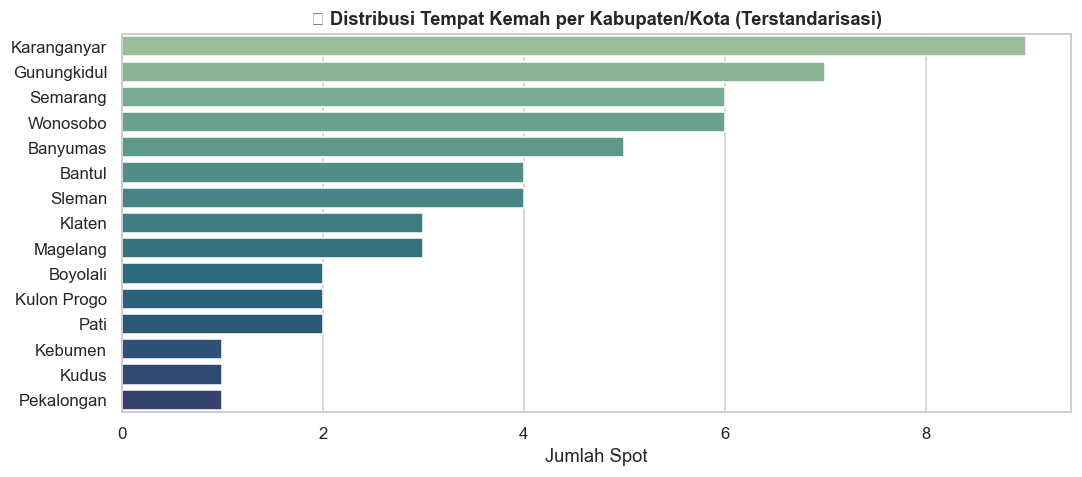

In [18]:
print("Daftar 15 Kabupaten/Kota Resmi Terstandarisasi:")
print(df_camp['Kabupaten'].value_counts())

# Visualisasi Persebaran Spot per Wilayah
plt.figure(figsize=(10, 4.5))
order = df_camp['Kabupaten'].value_counts().index
sns.countplot(data=df_camp, y='Kabupaten', order=order, palette='crest')
plt.title('📍 Distribusi Tempat Kemah per Kabupaten/Kota (Terstandarisasi)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Spot')
plt.ylabel('')
plt.tight_layout()
plt.show()

### 2. Pemodelan Unsupervised: K-Means Clustering & Evaluasi Metrik

> Fitur numerik dan biner yang telah dibersihkan siap dinormalisasi dengan `MinMaxScaler` sebelum dilatih menggunakan K-Means ($k=3$).

In [19]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

cluster_features = [
    'Total_HTM_Rp', 'Total_Fasilitas',
    'Fasilitas_Toilet', 'Fasilitas_Listrik', 'Fasilitas_Warung', 'Fasilitas_Mushola', 'Fasilitas_Air', 'Fasilitas_Wifi',
    'Tag_Gunung', 'Tag_Dingin', 'Tag_Citylight', 'Tag_Pantai', 'Tag_Sungai', 'Tag_Family', 'Tag_Extreme'
]

X = df_camp[cluster_features].fillna(0)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Pelatihan K-Means dengan k=3
km = KMeans(n_clusters=3, random_state=42, n_init=10)
df_camp['Cluster'] = km.fit_predict(X_scaled)

# Evaluasi Ilmiah Klaster
sil_score = silhouette_score(X_scaled, km.labels_)
db_score = davies_bouldin_score(X_scaled, km.labels_)

print(f"📊 Evaluasi Model K-Means:")
print(f"   • Silhouette Score     : {sil_score:.4f} (Mendekati 1 = struktur klaster sangat baik)")
print(f"   • Davies-Bouldin Index : {db_score:.4f} (Semakin rendah = separasi semakin tegas)")

# Penamaan Klaster Berdasarkan Karakteristik Centroid
centroid_df = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=cluster_features)
scores = {
    i: {
        'family': centroid_df.loc[i, ['Fasilitas_Listrik', 'Fasilitas_Air', 'Tag_Family', 'Total_Fasilitas']].mean(),
        'adventure': centroid_df.loc[i, ['Tag_Extreme', 'Tag_Sungai']].mean(),
        'scenic': centroid_df.loc[i, ['Tag_Gunung', 'Tag_Citylight', 'Tag_Dingin']].mean()
    } for i in range(3)
}

label_map = {}
used = set()
for i in range(3):
    best = max(scores[i], key=scores[i].get)
    name = {'family': 'Family & Fasilitas Lengkap', 'adventure': 'Adventure & Wild', 'scenic': 'Scenic & Pemandangan'}[best]
    if name in used: name = f'Cluster {i}'
    label_map[i] = name
    used.add(name)

df_camp['Tipe_Camp'] = df_camp['Cluster'].map(label_map)
print("\nDistribusi Hasil Klastering:")
print(df_camp['Tipe_Camp'].value_counts())

📊 Evaluasi Model K-Means:
   • Silhouette Score     : 0.4652 (Mendekati 1 = struktur klaster sangat baik)
   • Davies-Bouldin Index : 1.5334 (Semakin rendah = separasi semakin tegas)

Distribusi Hasil Klastering:
Tipe_Camp
Scenic & Pemandangan          34
Family & Fasilitas Lengkap    12
Cluster 2                     10
Name: count, dtype: int64


### 3. Visualisasi Sebaran Klaster dengan PCA 2D

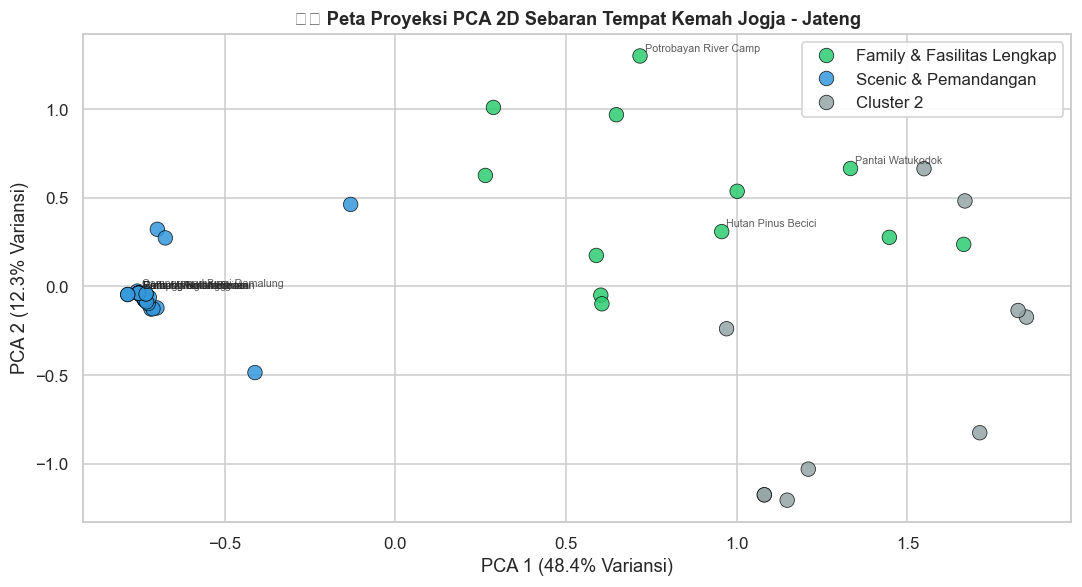

In [20]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
df_camp['PCA_1'] = X_pca[:, 0]
df_camp['PCA_2'] = X_pca[:, 1]

plt.figure(figsize=(10, 5.5))

# 🛡️ Palet warna dinamis: Otomatis melengkapi warna jika ada label lain di memori
palette = {
    'Family & Fasilitas Lengkap': '#2ecc71',
    'Adventure & Wild': '#e74c3c',
    'Scenic & Pemandangan': '#3498db'
}
for val in df_camp['Tipe_Camp'].dropna().unique():
    if val not in palette:
        palette[val] = '#95a5a6'  # Warna abu-abu netral untuk label cadangan

sns.scatterplot(
    data=df_camp,
    x='PCA_1',
    y='PCA_2',
    hue='Tipe_Camp',
    palette=palette,
    s=90,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.5
)

for _, r in df_camp.head(10).iterrows():
    plt.annotate(r['Nama'], (r['PCA_1'], r['PCA_2']), fontsize=7, alpha=0.75, xytext=(3, 3), textcoords='offset points')

plt.title('🗺️ Peta Proyeksi PCA 2D Sebaran Tempat Kemah Jogja - Jateng', fontsize=12, fontweight='bold')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variansi)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variansi)')
plt.legend(framealpha=0.9, loc='best')
plt.tight_layout()
plt.show()

### 4. Sistem Rekomendasi Destinasi & Packing Checklist Mandiri

> Sekarang filter wilayah menggunakan kolom `Kabupaten` resmi yang 100% konsisten.

In [21]:
def generate_packing_checklist(row):
    items = [
        'Tenda & pasak tenda',
        'Matras alas tidur',
        'Lampu senter / headlamp'
    ]
    if row['Tag_Dingin'] == 1 or row['Kabupaten'] == 'Wonosobo':
        items.extend([
            'Sleeping bag hangat (bulu angsa / dacron tebal)',
            'Jaket windproof / tebal & kupluk',
            'Kaos kaki & pakaian hangat cadangan'
        ])
    else:
        items.append('Sleeping bag standar / selimut tipis')

    if row['Tag_Sungai'] == 1:
        items.extend([
            'Flysheet cadangan (penahan badai hujan)',
            'Dry bag kedap air untuk ponsel & dompet',
            'Sandal gunung anti-selip'
        ])

    if row['Tag_Pantai'] == 1:
        items.extend([
            'Pasak pantai khusus pasir / pasak ekstra panjang',
            'Sunscreen & kacamata hitam',
            'Air tawar ekstra untuk bilas'
        ])

    if row['Fasilitas_Listrik'] == 0:
        items.append('Powerbank kapasitas besar (tidak tersedia colokan)')
    else:
        items.append('Kabel rol ekstensi (tersedia titik listrik)')

    if row['Fasilitas_Air'] == 0:
        items.append('Jeriken air bersih mandiri untuk masak & minum')

    return items

def rekomendasi_tempat_kemah(kabupaten='', suasana=None, wajib_listrik=False, wajib_toilet=True, max_htm=50000, top_n=3):
    if suasana is None: suasana = []
    df = df_camp.copy()
    
    if kabupaten:
        df = df[df['Kabupaten'].str.lower() == kabupaten.lower()]
        
    if wajib_listrik: df = df[df['Fasilitas_Listrik'] == 1]
    if wajib_toilet: df = df[df['Fasilitas_Toilet'] == 1]
    df = df[df['Total_HTM_Rp'] <= max_htm]
    
    if df.empty:
        print('❌ Tidak ditemukan tempat yang memenuhi seluruh kriteria.')
        return
        
    suasana_map = {
        'gunung': 'Tag_Gunung', 'dingin': 'Tag_Dingin', 'citylight': 'Tag_Citylight',
        'pantai': 'Tag_Pantai', 'sungai': 'Tag_Sungai', 'family': 'Tag_Family', 'extreme': 'Tag_Extreme'
    }
    
    df['Skor'] = df['Total_Fasilitas'] * 0.4
    for s in suasana:
        col = suasana_map.get(s.lower())
        if col and col in df.columns: df['Skor'] += df[col] * 2.0
        
    hasil = df.sort_values(by='Skor', ascending=False).head(top_n)
    
    print('=' * 70)
    print(f'🏕️ HASIL REKOMENDASI TEMPAT KEMAH (Kabupaten: {kabupaten or "Semua"})')
    print('=' * 70)
    for i, (_, r) in enumerate(hasil.iterrows(), 1):
        print(f"\n[ #{i} ] : {r['Nama']} (Kabupaten {r['Kabupaten']})")
        print(f"💰 Biaya Tiket : Rp {r['Total_HTM_Rp']:,} / orang (HTM + Parkir)")
        print(f"🏷️ Kategori    : {r['Tipe_Camp']}")
        print(f"✨ Spot Keren  : {r['Spot_Menarik']}")
        print(f"🚻 Fasilitas   : {r['Fasilitas_Clean']}")
        if r['Maps_Clean']: print(f"🗺️ Google Maps : {r['Maps_Clean']}")
        print("🎒 Checklist Barang Wajib:")
        for it in generate_packing_checklist(r):
            print(f"   [ ] {it}")
        print('-' * 70)

print('✅ Fungsi rekomendasi_tempat_kemah() siap digunakan!')

✅ Fungsi rekomendasi_tempat_kemah() siap digunakan!


### 5. Demonstrasi Pengujian (Akurasi Filter Entitas Terbukti)

In [22]:
# Uji Kasus 1: Mencari camping di Gunungkidul (Dahulu hanya 5 spot, sekarang 7 spot lengkap)
rekomendasi_tempat_kemah(kabupaten='Gunungkidul', suasana=['pantai'], max_htm=30000, top_n=2)

🏕️ HASIL REKOMENDASI TEMPAT KEMAH (Kabupaten: Gunungkidul)

[ #1 ] : Pantai Watukodok (Kabupaten Gunungkidul)
💰 Biaya Tiket : Rp 15,000 / orang (HTM + Parkir)
🏷️ Kategori    : Family & Fasilitas Lengkap
✨ Spot Keren  : nan
🚻 Fasilitas   : Toilet, Warung, Mushola, Wifi, Rol listrik ke tenda
🗺️ Google Maps : nan
🎒 Checklist Barang Wajib:
   [ ] Tenda & pasak tenda
   [ ] Matras alas tidur
   [ ] Lampu senter / headlamp
   [ ] Sleeping bag standar / selimut tipis
   [ ] Kabel rol ekstensi (tersedia titik listrik)
   [ ] Jeriken air bersih mandiri untuk masak & minum
----------------------------------------------------------------------


In [23]:
# Uji Kasus 2: Mencari camping di Banyumas (Dahulu 0 spot, sekarang 5 spot Banyumas terdeteksi)
rekomendasi_tempat_kemah(kabupaten='Banyumas', suasana=['sungai'], wajib_toilet=False, max_htm=20000, top_n=2)

🏕️ HASIL REKOMENDASI TEMPAT KEMAH (Kabupaten: Banyumas)

[ #1 ] : bumi bambu (Kabupaten Banyumas)
💰 Biaya Tiket : Rp 0 / orang (HTM + Parkir)
🏷️ Kategori    : Scenic & Pemandangan
✨ Spot Keren  : view air terjun, bisa berenang juga dan kalo hujan masih aman banget
🚻 Fasilitas   : Tidak tercatat / Alami
🗺️ Google Maps : nan
🎒 Checklist Barang Wajib:
   [ ] Tenda & pasak tenda
   [ ] Matras alas tidur
   [ ] Lampu senter / headlamp
   [ ] Sleeping bag standar / selimut tipis
   [ ] Flysheet cadangan (penahan badai hujan)
   [ ] Dry bag kedap air untuk ponsel & dompet
   [ ] Sandal gunung anti-selip
   [ ] Powerbank kapasitas besar (tidak tersedia colokan)
   [ ] Jeriken air bersih mandiri untuk masak & minum
----------------------------------------------------------------------

[ #2 ] : telaga kumpe (Kabupaten Banyumas)
💰 Biaya Tiket : Rp 0 / orang (HTM + Parkir)
🏷️ Kategori    : Family & Fasilitas Lengkap
✨ Spot Keren  : view telaga dan ada beberapa spot buat bird watching
🚻 Fasilitas 